
# 3. Customer Segmentation

## 3.1 Data Preparation

Customer segmentation is an unsupervised machine learning task.

Our goal is to identify customer groups based on purchasing behavior.

We will use customer-level features such as:

- Purchase frequency
- Total spending
- Average basket value
- Purchase recency
- Product diversity
- Average basket size

We will use the last 365 days of available transaction data.

RFM segment labels will not be used as model features.


In [1]:
from pathlib import Path
import sys
from sqlalchemy import text
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.database import get_engine

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

engine = get_engine()

In [2]:
SNAPSHOT_DAY = 712
OBSERVATION_DAYS = 365

START_DAY = SNAPSHOT_DAY - OBSERVATION_DAYS
END_DAY = SNAPSHOT_DAY - 1

# Load basket-level data from MySQL
query = text("""
    SELECT
        household_key,
        BASKET_ID,
        MIN(`DAY`) AS basket_day,
        COUNT(*) AS basket_lines,
        COUNT(DISTINCT PRODUCT_ID) AS unique_products,
        SUM(SALES_VALUE) AS basket_sales

    FROM raw_transaction_data

    WHERE `DAY` BETWEEN :start_day AND :end_day

    GROUP BY household_key, BASKET_ID

    HAVING SUM(SALES_VALUE) > 0
""")

with engine.connect() as connection:
    seg_baskets = pd.read_sql_query(
        query,
        con=connection,
        params={
            "start_day": START_DAY,
            "end_day": END_DAY,
        },
    )

# Convert sales values to numeric
seg_baskets["basket_sales"] = pd.to_numeric(
    seg_baskets["basket_sales"]
)

print("Dataset Shape:", seg_baskets.shape)

print(
    "Unique Households:",
    seg_baskets["household_key"].nunique()
)

display(seg_baskets.head())

Dataset Shape: (154910, 6)
Unique Households: 2479


,household_key,BASKET_ID,basket_day,basket_lines,unique_products,basket_sales
0,1,32161545571,352,26,26,68.80
1,1,32259826179,361,37,37,97.57
2,1,32556765955,375,1,1,1.39
3,1,32556766238,375,36,36,89.32
4,1,32759995726,389,1,1,7.99



## 3.2 Customer-Level Feature Engineering

Feature engineering is the process of creating useful variables from raw data.

In this section, we will convert basket-level data into customer-level data.

Each row will represent one household.

We will calculate purchase frequency, total spending, average basket value, active days, average basket size, and recency.

These features will help us identify different customer groups using machine learning.


In [3]:
# Aggregate basket-level data by customer
customer_features = (
    seg_baskets
    .groupby("household_key", as_index=False)
    .agg(
        purchase_frequency=("BASKET_ID", "nunique"),
        total_spending=("basket_sales", "sum"),
        avg_basket_value=("basket_sales", "mean"),
        active_days=("basket_day", "nunique"),
        avg_basket_lines=("basket_lines", "mean"),
        avg_unique_products_per_basket=("unique_products", "mean"),
        last_purchase_day=("basket_day", "max")
    )
)

# Calculate purchase recency
customer_features["recency"] = (
    SNAPSHOT_DAY - customer_features["last_purchase_day"]
)

# Remove the temporary column
customer_features = customer_features.drop(
    columns="last_purchase_day"
)

# Validate the customer dataset
assert customer_features["household_key"].is_unique

print("Customer Dataset Shape:", customer_features.shape)

display(customer_features.head(10))


Customer Dataset Shape: (2479, 8)


,household_key,purchase_frequency,total_spending,avg_basket_value,active_days,avg_basket_lines,avg_unique_products_per_basket,recency
0,1,52,"2,484.87",47.79,47,18.88,18.88,6
1,2,17,964.15,56.71,17,21.12,21.12,44
2,3,19,763.89,40.20,19,16.47,16.47,9
3,4,12,242.23,20.19,12,4.92,4.92,85
4,5,18,273.47,15.19,15,3.61,3.61,9
5,6,156,"3,387.96",21.72,137,6.11,6.11,5
6,7,40,"2,520.74",63.02,40,24.27,24.27,3
7,8,69,"3,498.76",50.71,62,18.61,18.61,6
8,9,13,540.65,41.59,13,11.77,11.77,23
9,10,3,100.36,33.45,3,8.67,8.67,27


In [4]:
# Check missing values
print("Missing Values:")
display(customer_features.isna().sum())

# Check descriptive statistics
display(
    customer_features
    .drop(columns="household_key")
    .describe()
    .T
    .round(2)
)

# Check unique customers
print(
    "Unique Customers:",
    customer_features["household_key"].nunique()
)

Missing Values:


household_key                     0
purchase_frequency                0
total_spending                    0
avg_basket_value                  0
active_days                       0
avg_basket_lines                  0
avg_unique_products_per_basket    0
recency                           0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
purchase_frequency,"2,479.00",62.49,67.96,1.00,20.00,43.00,83.00,721.00
total_spending,"2,479.00","1,874.49","2,035.29",5.50,482.11,"1,216.18","2,561.02","26,771.59"
avg_basket_value,"2,479.00",32.30,20.79,1.31,18.13,27.83,41.30,198.56
active_days,"2,479.00",51.33,45.42,1.00,18.00,39.00,72.00,304.00
avg_basket_lines,"2,479.00",10.41,6.66,1.00,5.96,8.89,13.12,64.00
avg_unique_products_per_basket,"2,479.00",10.41,6.66,1.00,5.96,8.89,13.12,64.00
recency,"2,479.00",22.46,43.19,1.00,2.00,7.00,20.00,341.00


Unique Customers: 2479



## 3.3 Feature Correlation and Redundancy

Before clustering, we need to understand the relationships between customer features.

Highly correlated features may contain similar information.

We will use Spearman correlation because our customer variables have skewed distributions.

We will also check whether some features contain identical values.

Our goal is to select useful features for K-Means clustering.


Basket features are identical: True


,purchase_frequency,total_spending,avg_basket_value,active_days,avg_basket_lines,avg_unique_products_per_basket,recency
purchase_frequency,1.00,0.86,0.02,1.00,0.03,0.03,-0.59
total_spending,0.86,1.00,0.48,0.86,0.44,0.44,-0.52
avg_basket_value,0.02,0.48,1.00,0.02,0.89,0.89,-0.04
active_days,1.00,0.86,0.02,1.00,0.04,0.04,-0.59
avg_basket_lines,0.03,0.44,0.89,0.04,1.00,1.00,-0.05
avg_unique_products_per_basket,0.03,0.44,0.89,0.04,1.00,1.00,-0.05
recency,-0.59,-0.52,-0.04,-0.59,-0.05,-0.05,1.00


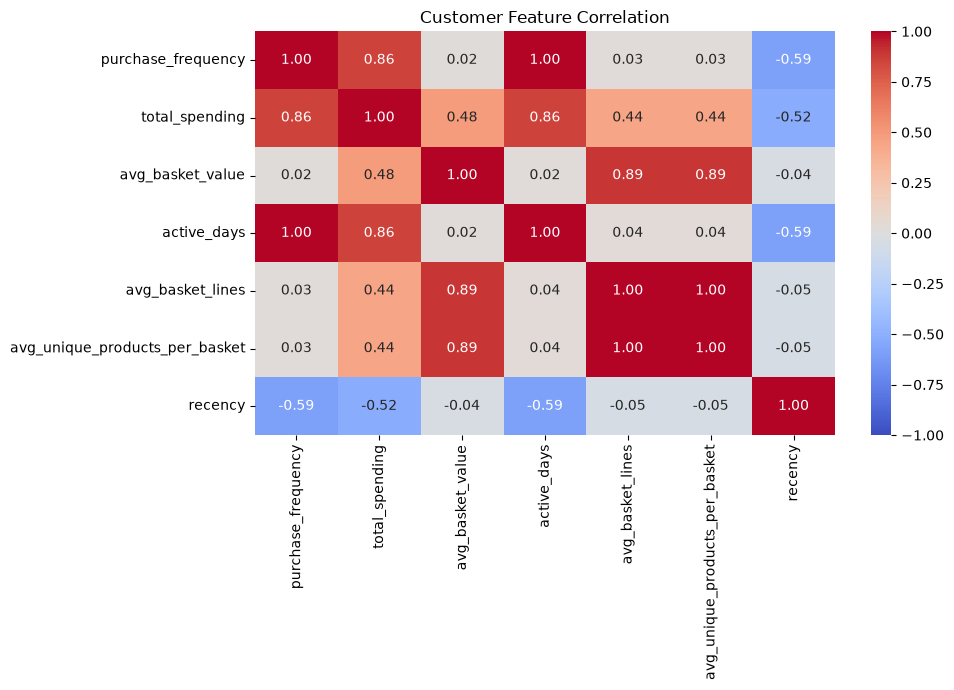

In [5]:
# 1. Check whether basket features are identical
basket_lines = customer_features["avg_basket_lines"]

unique_products = customer_features[
    "avg_unique_products_per_basket"
]

identical_features = np.allclose(
    basket_lines,
    unique_products
)

print("Basket features are identical:", identical_features)

# 2. Select numerical features
feature_cols = customer_features.columns.drop(
    "household_key"
)

# 3. Calculate Spearman correlation
correlation_matrix = (
    customer_features[feature_cols]
    .corr(method="spearman")
)

display(correlation_matrix.round(2))

# 4. Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Customer Feature Correlation")
plt.tight_layout()
plt.show()



## 3.4 Feature Selection

We found strong correlations between some customer features.

Purchase frequency and active days contain very similar information.

Average basket lines and average unique products are identical in our dataset.

To reduce redundant information, we will select three features:

- Purchase frequency
- Average basket value
- Recency

We will keep total spending and other variables for cluster profiling.

Our goal is to create a simple and interpretable K-Means model.


In [6]:
# Select features for clustering
selected_features = [
    "purchase_frequency",
    "avg_basket_value",
    "recency",
]

# Create the feature matrix
X = customer_features[selected_features].copy()

# Validate the feature matrix
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()
assert X.ge(0).all().all()

print("Feature Matrix Shape:", X.shape)

display(X.head())

Feature Matrix Shape: (2479, 3)


,purchase_frequency,avg_basket_value,recency
0,52,47.79,6
1,17,56.71,44
2,19,40.20,9
3,12,20.19,85
4,18,15.19,9



## 3.5 Feature Transformation and Scaling

K-Means is a distance-based clustering algorithm.

Features with large values may have more influence on the distance calculations.

We will apply two preprocessing steps:

1. Log transformation to reduce right-skewed distributions.
2. StandardScaler to standardize feature values.

We will use a scikit-learn Pipeline to combine these steps.

The original customer features will remain unchanged.


In [7]:
# Create the preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        (
            "log_transform",
            FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Fit and transform selected features
X_scaled = preprocessing_pipeline.fit_transform(X)

# Convert the result into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=selected_features,
    index=X.index,
)

print("Scaled Feature Matrix:", X_scaled_df.shape)

display(X_scaled_df.head())

# Check scaled feature statistics
display(
    X_scaled_df.agg(["mean", "std"]).round(3)
)

Scaled Feature Matrix: (2479, 3)


,purchase_frequency,avg_basket_value,recency
0,0.28,0.93,-0.25
1,-0.75,1.21,1.25
2,-0.65,0.65,0.04
3,-1.07,-0.47,1.77
4,-0.70,-0.92,0.04


,purchase_frequency,avg_basket_value,recency
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00



## 3.6 Finding the Optimal Number of Clusters

K-Means groups customers based on similarities in their features.

Before training the final model, we need to choose the number of clusters.

We will test cluster numbers from 2 to 8.

We will use two evaluation methods:

- Elbow Method: Measures the variation within clusters.
- Silhouette Score: Measures how well clusters are separated.

We will also check cluster sizes to avoid creating very small customer groups.


In [8]:
# Define cluster numbers
k_values = range(2, 9)

results = []

for k in k_values:

    # Initialize K-Means
    model = KMeans(
        n_clusters=k,
        random_state=42,
        # Runs K-Means 20 times with different starting centroids and selects the best result by inertia
        n_init=20,
    )

    # Train the model and assign cluster labels
    labels = model.fit_predict(X_scaled)

    # Calculate Silhouette Score
    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=1200,
        random_state=42
    )

    # Check the smallest cluster
    cluster_sizes = pd.Series(labels).value_counts()

    results.append({
        "k": k,
        # Inertia measures the total squared distance between observations and their assigned cluster centers.
        # Lower inertia means customers are closer to their cluster centers.
        "inertia": model.inertia_,
        "silhouette_score": silhouette,
        "smallest_cluster": cluster_sizes.min(),
    })


# Create evaluation DataFrame
k_evaluation = pd.DataFrame(results)

display(k_evaluation.round(3))

,k,inertia,silhouette_score,smallest_cluster
0,2,"4,726.74",0.34,899
1,3,"3,719.78",0.27,704
2,4,"3,125.17",0.24,440
3,5,"2,680.82",0.26,249
4,6,"2,416.21",0.24,244
5,7,"2,188.99",0.24,219
6,8,"2,013.58",0.24,196


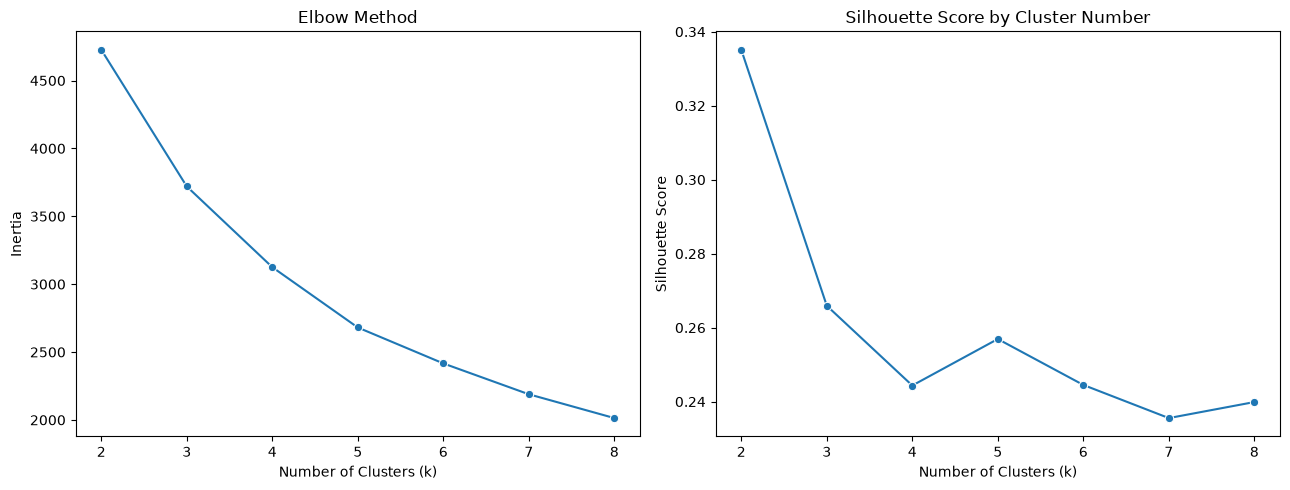

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow Method
sns.lineplot(
    data=k_evaluation,
    x="k",
    y="inertia",
    marker="o",
    ax=axes[0],
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

# Silhouette Score
sns.lineplot(
    data=k_evaluation,
    x="k",
    y="silhouette_score",
    marker="o",
    ax=axes[1],
)

axes[1].set_title("Silhouette Score by Cluster Number")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()



## 3.7 Final K-Means Model Training

We tested different cluster numbers from 2 to 8.

K = 2 achieved the highest Silhouette Score of 0.34.

We will use two clusters for our first customer segmentation model.

The final Pipeline includes:

1. Log transformation
2. StandardScaler
3. K-Means clustering

After training, we will analyze the customer behavior in each cluster.


In [10]:
# Define the selected number of clusters
OPTIMAL_K = 2

# Create the final clustering pipeline
segmentation_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessing_pipeline),
        (
            "kmeans",
            KMeans(
                n_clusters=OPTIMAL_K,
                random_state=42,
                n_init=20
            ),
        ),
    ]
)

# Train the pipeline and assign clusters
cluster_labels = segmentation_pipeline.fit_predict(X)

# Create a customer-level result dataset
segmented_customers = customer_features.copy()

segmented_customers["cluster"] = cluster_labels

# Validate cluster assignments
assert len(segmented_customers) == len(X)
assert segmented_customers["cluster"].nunique() == OPTIMAL_K
assert segmented_customers["cluster"].notna().all()

print("Final Cluster Distribution:")

display(
    segmented_customers["cluster"]
    .value_counts()
    .sort_index()
)

display(segmented_customers.head())

Final Cluster Distribution:


cluster
0    1580
1     899
Name: count, dtype: int64

,household_key,purchase_frequency,total_spending,avg_basket_value,active_days,avg_basket_lines,avg_unique_products_per_basket,recency,cluster
0,1,52,"2,484.87",47.79,47,18.88,18.88,6,0
1,2,17,964.15,56.71,17,21.12,21.12,44,1
2,3,19,763.89,40.20,19,16.47,16.47,9,1
3,4,12,242.23,20.19,12,4.92,4.92,85,1
4,5,18,273.47,15.19,15,3.61,3.61,9,1



## 3.8 Cluster Profiling

After training K-Means, we need to understand each cluster.

We will compare customer groups using their original behavioral features.

We will analyze:

- Number of customers
- Purchase frequency
- Total spending
- Average basket value
- Recency
- Active shopping days

Our goal is to identify the main characteristics of each customer cluster.

We will assign meaningful business names after reviewing the results.


In [11]:
# Calculate customer statistics for each cluster
cluster_profile = (
    segmented_customers
    .groupby("cluster")
    .agg(
        customer_count=("household_key", "size"),
        median_frequency=("purchase_frequency", "median"),
        median_basket_value=("avg_basket_value", "median"),
        median_recency=("recency", "median"),
        median_active_days=("active_days", "median"),
        avg_total_spending=("total_spending", "mean"),
        total_spending=("total_spending", "sum"),
    )
)

# Calculate customer share
cluster_profile["customer_share_pct"] = (
    cluster_profile["customer_count"]
    / len(segmented_customers)
    * 100
)

# Calculate spending share
cluster_profile["spending_share_pct"] = (
    cluster_profile["total_spending"]
    / cluster_profile["total_spending"].sum()
    * 100
)

display(cluster_profile.round(2))

,customer_count,median_frequency,median_basket_value,median_recency,median_active_days,avg_total_spending,total_spending,customer_share_pct,spending_share_pct
cluster,,,,,,,,,
0,1580,67.00,29.29,3.00,59.00,"2,614.31","4,130,601.97",63.74,88.89
1,899,16.00,24.21,29.00,14.00,574.25,"516,250.65",36.26,11.11



## 3.9 Cluster Interpretation and Visualization

The K-Means model identified two customer groups.

**Cluster 0: Frequent & Recent Shoppers**
- Higher purchase frequency
- More recent purchases
- Higher average total spending
- Larger contribution to total revenue

**Cluster 1: Less Active Shoppers**
- Lower purchase frequency
- Longer purchase recency
- Lower average total spending
- Smaller contribution to total revenue

We will compare customer share and spending share to understand the business importance of each cluster.

These clusters describe customer behavior. They do not represent predicted churn risk.


In [12]:
# Define business names for each cluster
cluster_names = {
    0: "Frequent & Recent Shoppers",
    1: "Less Active Shoppers",
}

# Add cluster names to customer data
segmented_customers["cluster_name"] = (
    segmented_customers["cluster"].map(cluster_names)
)

# Add names to cluster profile
cluster_profile = cluster_profile.copy()

cluster_profile["cluster_name"] = (
    cluster_profile.index.map(cluster_names)
)

# Validate cluster labels
assert segmented_customers["cluster_name"].notna().all()

display(cluster_profile.round(2))

,customer_count,median_frequency,median_basket_value,median_recency,median_active_days,avg_total_spending,total_spending,customer_share_pct,spending_share_pct,cluster_name
cluster,,,,,,,,,,
0,1580,67.00,29.29,3.00,59.00,"2,614.31","4,130,601.97",63.74,88.89,Frequent & Recent Shoppers
1,899,16.00,24.21,29.00,14.00,574.25,"516,250.65",36.26,11.11,Less Active Shoppers


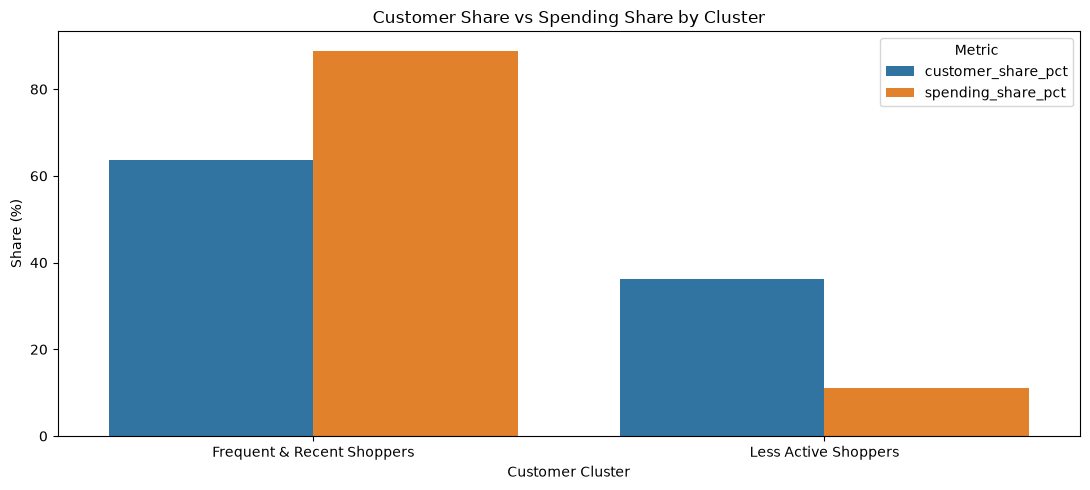

In [13]:
# Prepare data for visualization
cluster_plot_df = (
    cluster_profile
    .reset_index()
    .melt(
        id_vars="cluster_name",
        value_vars=[
            "customer_share_pct",
            "spending_share_pct"
        ],
        var_name="metric",
        value_name="share_pct"
    )
)

# Create comparison chart
plt.figure(figsize=(11, 5))

sns.barplot(
    data=cluster_plot_df,
    x="cluster_name",
    y="share_pct",
    hue="metric",
    errorbar=None,
)

plt.title("Customer Share vs Spending Share by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Share (%)")
plt.legend(title="Metric")

plt.tight_layout()
plt.show()


## 3.10 RFM vs K-Means Comparison

We will compare rule-based RFM segmentation with machine learning-based customer clustering.

RFM uses Recency, Frequency, and Monetary scores.

K-Means uses Purchase Frequency, Average Basket Value, and Recency.

Our goals are to:

- Compare customer groups from both methods.
- Identify similarities between RFM segments and K-Means clusters.
- Understand whether both methods describe similar customer behaviors.

Both analyses use snapshot day 712.


In [15]:
# Load RFM segmentation results
rfm_segments = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "rfm_segments.csv"
)

# Merge RFM and K-Means results
comparison_df = segmented_customers[
    ["household_key", "cluster", "cluster_name"]
].merge(
    rfm_segments[
        ["household_key", "segment"]
    ],
    on="household_key",
    how="left",
    validate="one_to_one",
)

# Validate customer matching
assert len(comparison_df) == 2479
assert comparison_df["segment"].notna().all()
assert comparison_df["household_key"].is_unique

display(comparison_df.head())

,household_key,cluster,cluster_name,segment
0,1,0,Frequent & Recent Shoppers,Recently Active
1,2,1,Less Active Shoppers,Less Recent - Infrequent
2,3,1,Less Active Shoppers,Recently Active
3,4,1,Less Active Shoppers,Less Recent - Infrequent
4,5,1,Less Active Shoppers,Recently Active


In [16]:
# Calculate customer counts
rfm_cluster_counts = pd.crosstab(
    comparison_df["segment"],
    comparison_df["cluster_name"],
)

print("RFM vs K-Means — Customer Counts")
display(rfm_cluster_counts)

# Calculate percentages within each RFM segment
rfm_cluster_pct = pd.crosstab(
    comparison_df["segment"],
    comparison_df["cluster_name"],
    normalize="index",
) * 100

print("\nRFM vs K-Means — Row Percentages")
display(rfm_cluster_pct.round(2))

RFM vs K-Means — Customer Counts


cluster_name,Frequent & Recent Shoppers,Less Active Shoppers
segment,,
Champions,533,0
Less Recent - Frequent,150,161
Less Recent - Infrequent,7,636
Loyal Customers,117,0
Potential Loyalists,286,0
Recent Low Frequency,29,15
Recently Active,458,87



RFM vs K-Means — Row Percentages


cluster_name,Frequent & Recent Shoppers,Less Active Shoppers
segment,,
Champions,100.00,0.00
Less Recent - Frequent,48.23,51.77
Less Recent - Infrequent,1.09,98.91
Loyal Customers,100.00,0.00
Potential Loyalists,100.00,0.00
Recent Low Frequency,65.91,34.09
Recently Active,84.04,15.96


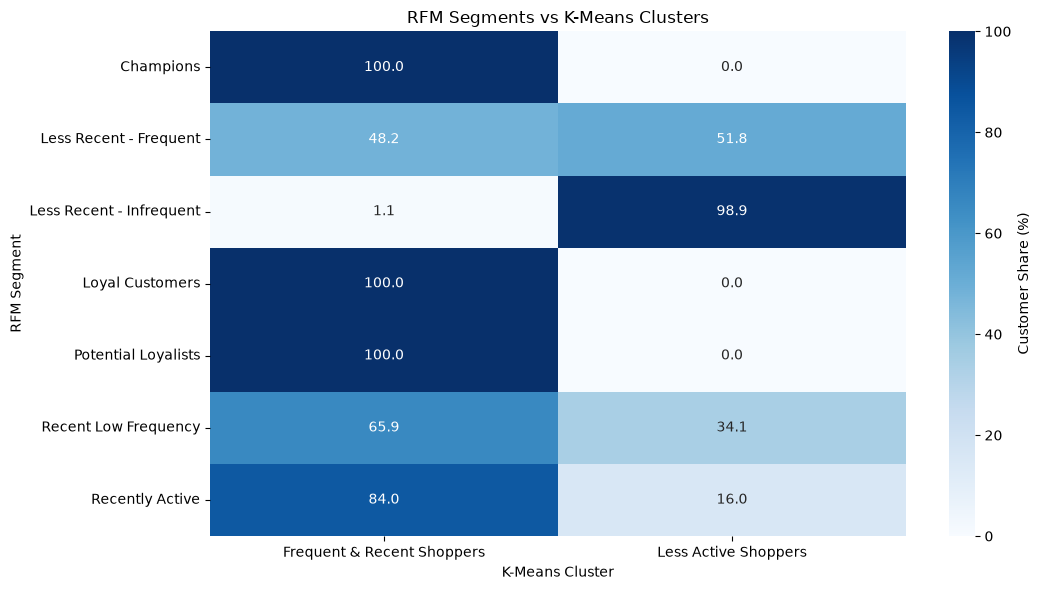

In [17]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    rfm_cluster_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Customer Share (%)"},
)

plt.title("RFM Segments vs K-Means Clusters")
plt.xlabel("K-Means Cluster")
plt.ylabel("RFM Segment")

plt.tight_layout()
plt.show()


## 3.11 Key Findings and Conclusions

### Customer Segmentation Results

We analyzed 2,479 households using purchasing behavior from the last 365 days.

We selected three features for K-Means clustering:

- Purchase Frequency
- Average Basket Value
- Recency

We applied log transformation and StandardScaler before clustering.

### K-Means Model

We tested cluster numbers from 2 to 8.

K = 2 achieved the highest Silhouette Score of 0.34.

The model identified two customer groups:

**Cluster 0: Frequent & Recent Shoppers**
- 1,580 customers (63.74%)
- 88.89% of observed spending
- Median purchase frequency: 67
- Median recency: 3 days

**Cluster 1: Less Active Shoppers**
- 899 customers (36.26%)
- 11.11% of observed spending
- Median purchase frequency: 16
- Median recency: 29 days

### RFM vs K-Means

The two segmentation methods showed similar customer behavior patterns.

- All Champions belong to the Frequent & Recent Shoppers cluster.
- All Loyal Customers belong to the Frequent & Recent Shoppers cluster.
- 98.91% of Less Recent - Infrequent customers belong to the Less Active Shoppers cluster.

The methods share similar behavioral features, so these results are not independent validation.

### Business Insights

Frequent & Recent Shoppers generate most of the observed spending.

The business may focus on keeping these customers active through loyalty programs and personalized offers.

Less Active Shoppers may benefit from targeted engagement campaigns.

However, these recommendations are hypotheses. Their impact should be tested before implementation.

### Limitations

- The Silhouette Score of 0.34 indicates moderate cluster separation.
- K-Means clusters do not represent predicted churn risk.
- Customers without positive purchases in the last 365 days were excluded from clustering.
- Cluster stability and business impact have not been tested.

### Conclusion

K-Means identified two broad customer behavior groups.

The clustering results are useful for exploratory customer analysis and support our RFM findings.

The next step is Customer Churn Prediction using supervised machine learning.


In [18]:

# Create the output directory
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Keep customer identifiers and cluster labels
cluster_export = segmented_customers[
    ["household_key", "cluster", "cluster_name"]
].copy()

# Add customers without recent positive purchases
customer_segments = rfm_segments[
    ["household_key", "segment"]
].merge(
    cluster_export,
    on="household_key",
    how="left",
    validate="one_to_one",
)

customer_segments["cluster_name"] = (
    customer_segments["cluster_name"].fillna(
        "No Positive Purchases (365d)"
    )
)

# Validate the final customer table
assert len(customer_segments) == 2500
assert customer_segments["household_key"].is_unique

# Save results
customer_segments.to_csv(
    output_dir / "customer_segments.csv",
    index=False,
)

print("Customer Segmentation Results Saved")
print("Total Customers:", len(customer_segments))

display(customer_segments["cluster_name"].value_counts())


Customer Segmentation Results Saved
Total Customers: 2500


cluster_name
Frequent & Recent Shoppers      1580
Less Active Shoppers             899
No Positive Purchases (365d)      21
Name: count, dtype: int64